# Ethereum Gas Fee Study

**Question:** When is the cheapest time to send a transaction on Ethereum, how much could a company save by timing it, and what causes fee spikes?

**Data:** hourly summary of Ethereum blocks, Jan to Sep 2026, pulled from BigQuery with [`sql/hourly_gas.sql`](../sql/hourly_gas.sql) and saved as `data/gas_hourly.csv`.

## Step 2: Check the data

Load the hourly data and convert timestamps from UTC to New York time, so findings read as "weekday afternoons" rather than UTC hours.

In [1]:
import pandas as pd

df = pd.read_csv("../data/gas_hourly.csv")
df["hour"] = pd.to_datetime(df["hour"], utc=True).dt.tz_convert("America/New_York")
df.head()

,hour,blocks,avg_base_fee_gwei,tx_count,block_fullness
0,2025-12-31 19:00:00-05:00,299,0.035638,76759,0.506983
1,2025-12-31 20:00:00-05:00,300,0.030256,68399,0.511707
2,2025-12-31 21:00:00-05:00,299,0.031566,66667,0.512734
3,2025-12-31 22:00:00-05:00,297,0.031615,72503,0.505298
4,2025-12-31 23:00:00-05:00,299,0.029470,69984,0.510130


Run the checks. Two facts about Ethereum tell us what to expect: about one block every 12 seconds (about 300 per hour), and 9 months is about 6,550 hours.

In [2]:
print(len(df))                    # about 6,550?
print(df["blocks"].describe())    # mostly near 300?
print(df.isna().sum())            # anything missing?
print(df["avg_base_fee_gwei"].describe())

6552
count    6552.000000
mean      298.791972
std         1.182962
min       288.000000
25%       298.000000
50%       299.000000
75%       300.000000
max       300.000000
Name: blocks, dtype: float64
hour                 0
blocks               0
avg_base_fee_gwei    0
tx_count             0
block_fullness       0
dtype: int64
count    6552.000000
mean        0.267236
std         0.715701
min         0.026319
25%         0.058979
50%         0.111527
75%         0.195360
max        16.785048
Name: avg_base_fee_gwei, dtype: float64


### Data checks

- **Row count:** 6,552 hours, which is exactly 273 days × 24 hours from Jan 1 to Sep 30, 2026. No hours are missing.
- **Blocks per hour:** median 299, range 288 to 300. No suspicious hours, which fits one block every 12 seconds.
- **Missing values:** none in any column.
- **Fee range:** min 0.026 gwei, median 0.11 gwei, max 16.8 gwei. The max is about 150 times the median. These are real spikes to explain later, not errors to delete. The biggest ones cluster around Feb 5 and 6 and Sep 24.
- **Time zone:** converted from UTC to New York time so patterns read in business terms (for example "weekday afternoons") for a US company.

## Step 3: Explore

**My guess (written before looking at the data):**

I expect gas fees to be **highest in the morning and evening** (New York time) and **lowest overnight**.

**Why:** the morning and evening in New York overlap with trading hours in other parts of the world. Europe is active during the New York morning, and Asia opens during the New York evening. More traders online means more Ethereum transactions, which fills blocks and pushes the base fee up. Overnight in New York, fewer major markets are active, so demand and fees should drop.

Plot the hourly base fee across all 9 months to see the overall shape.

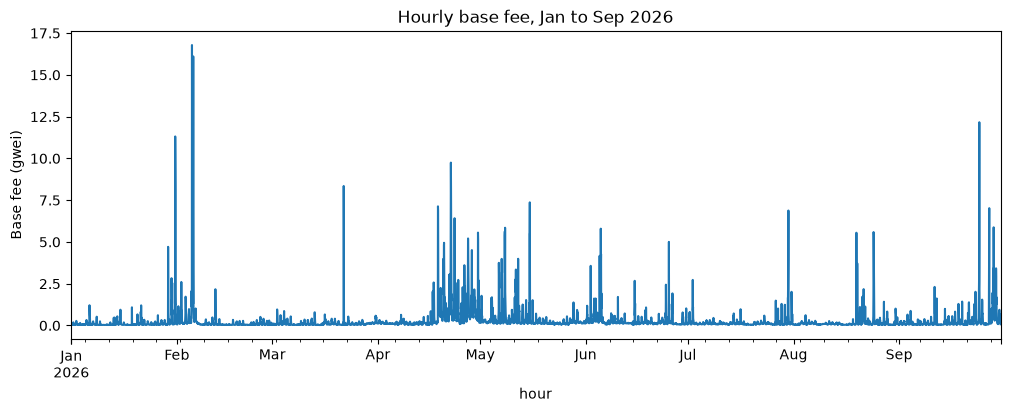

In [3]:
import matplotlib.pyplot as plt

df.set_index("hour")["avg_base_fee_gwei"].plot(figsize=(12, 4), title="Hourly base fee, Jan to Sep 2026")
plt.ylabel("Base fee (gwei)")
plt.show()

Compare the mean and median. If spikes pull the mean well above the median, the median is the better measure of a typical hour.

In [4]:
print("Mean:  ", round(df["avg_base_fee_gwei"].mean(), 3), "gwei")
print("Median:", round(df["avg_base_fee_gwei"].median(), 3), "gwei")

Mean:   0.267 gwei
Median: 0.112 gwei


### What I see

Fees sit near 0.1 gwei most of the time, with rare, sharp spikes up to about 17 gwei (early February, a busy stretch from mid April to mid May, and late September). Those spikes pull the mean (0.27 gwei) to more than double the median (0.11 gwei), so I'll use the **median** to describe a typical hour, because it isn't distorted by a handful of extreme hours.

## Step 4: Find the cheapest and most expensive times

A company needs a rule it can follow ("send on Sunday nights"), so arrange the data the way that decision is made: by **day of week** and **hour of day**. Each cell of the 7 × 24 grid is the **median** base fee for that slot.

In [5]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["hour_of_day"] = df["hour"].dt.hour
df["weekday"] = pd.Categorical(df["hour"].dt.day_name(), categories=order, ordered=True)

grid = df.pivot_table(index="weekday", columns="hour_of_day",
                      values="avg_base_fee_gwei", aggfunc="median", observed=False)

print("Cheapest slot:", grid.stack().idxmin(), round(grid.stack().min(), 3), "gwei")
print("Most expensive slot:", grid.stack().idxmax(), round(grid.stack().max(), 3), "gwei")
print("Ratio:", round(grid.stack().max() / grid.stack().min(), 1), "x")

Cheapest slot: ('Sunday', np.int32(22)) 0.058 gwei
Most expensive slot: ('Wednesday', np.int32(10)) 0.435 gwei
Ratio: 7.5 x


Draw the grid as a heatmap and save it for the README.

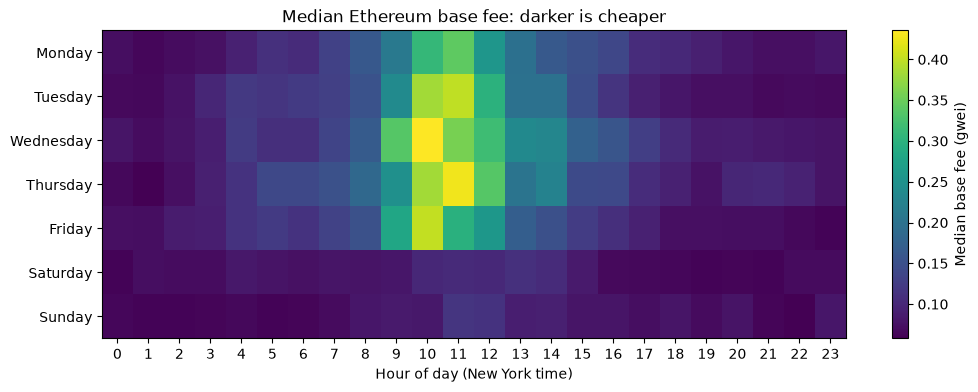

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(grid, aspect="auto", cmap="viridis")
ax.set_yticks(range(7))
ax.set_yticklabels(order)
ax.set_xticks(range(24))
ax.set_xlabel("Hour of day (New York time)")
ax.set_title("Median Ethereum base fee: darker is cheaper")
fig.colorbar(im, label="Median base fee (gwei)")
plt.savefig("../images/heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

Summarise the pattern by hour of day and by weekday.

In [7]:
print(grid.median(axis=0).round(3))   # typical fee by hour of day
print(grid.median(axis=1).round(3))   # typical fee by weekday

hour_of_day
0     0.068
1     0.066
2     0.073
3     0.089
4     0.113
5     0.111
6     0.109
7     0.131
8     0.154
9     0.238
10    0.383
11    0.342
12    0.258
13    0.197
14    0.163
15    0.142
16    0.115
17    0.093
18    0.080
19    0.073
20    0.077
21    0.072
22    0.069
23    0.078
dtype: float64
weekday
Monday       0.105
Tuesday      0.116
Wednesday    0.116
Thursday     0.126
Friday       0.111
Saturday     0.074
Sunday       0.075
dtype: float64


### Results vs. my guess

- **Cheapest:** Sunday around 10pm New York time (about 0.058 gwei). Evenings and overnight are cheap every day, and Saturday and Sunday are about 35% cheaper than weekdays.
- **Most expensive:** Wednesday around 10am New York time (about 0.435 gwei), roughly **7.5× the cheapest slot**. The peak runs from about 9am to 1pm on weekdays.
- **My guess:** partly right. I was right that **nights are cheap** and **mornings are expensive**, but wrong about **evenings**: New York evenings are among the cheapest hours. The peak lines up with the window when **US markets are open and Europe is still in its afternoon**, so the US and Europe overlap matters more than Asia's open. I also missed how much cheaper **weekends** are.